In [ ]:
import os
from glob import glob
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, cohen_kappa_score, precision_score, recall_score, f1_score

# IEXNet

In [ ]:
logs, tests = list(), list()

In [ ]:
log_subject_invariant = pd.read_csv("F:/Project-Motor Imagery Classification/Checkpoints/Channelwise_Input_IEXNet/train_log.csv")
log_subject_invariant = log_subject_invariant.drop(columns='Unnamed: 0')
test_results_subjectinvariant = pd.read_csv("F:/Project-Motor Imagery Classification/Checkpoints/Channelwise_Input_IEXNet/test_results.csv")
test_results_subjectinvariant = test_results_subjectinvariant.drop(columns='Unnamed: 0')

In [14]:
for i in [1,2,3,5,6,7,8,9]:
    dat = pd.read_csv(f"F:/Project-Motor Imagery Classification/Checkpoints/Channelwise_Input_IEXNet/train_log_sub{i}.csv")
    dat = dat.drop(columns='Unnamed: 0')
    logs.append(dat)
    dat = pd.read_csv(f"F:/Project-Motor Imagery Classification/Checkpoints/Channelwise_Input_IEXNet/test_results_{i}.csv")
    dat = dat.drop(columns='Unnamed: 0')
    tests.append(dat)
    del dat

In [15]:
test_results_subjectwise = pd.concat(tests, ignore_index=True)
test_results_subjectwise

,y_true,y_pred,accuracy
0,0,0,0.951389
1,3,3,0.951389
2,3,3,0.951389
3,1,1,0.951389
4,1,1,0.951389
...,...,...,...
18427,0,0,0.921875
18428,1,1,0.921875
18429,2,1,0.921875
18430,0,0,0.921875


In [16]:
len(logs)

8

In [17]:
logs[0].columns, tests[0].columns

(Index(['train_loss', 'val_loss', 'train_acc', 'val_acc', 'train_kappa',
        'val__kappa', 'lr'],
       dtype='object'),
 Index(['y_true', 'y_pred', 'accuracy'], dtype='object'))

In [18]:
for i in range(0,len(tests)):
    print(len(tests[i]))

2304
2304
2304
2304
2304
2304
2304
2304


In [19]:
train_accuracy, validation_accuracy, train_kappa, validation_kappa = list(), list(), list(), list()
for i in range(0, len(logs)):
    metric = logs[i]["train_acc"][len(logs[i]["train_acc"])-1]
#    print(f"Training Accuracy : {metric:.4f}")
    train_accuracy.append(metric)

    metric = logs[i]["val_acc"][len(logs[i]["val_acc"])-1]
#    print(f"Validation Accuracy : {metric:.4f}")
    validation_accuracy.append(metric)

    metric = logs[i]["train_kappa"][len(logs[i]["train_kappa"])-1]
#    print(f"Training Kappa : {metric:.4f}")
    train_kappa.append(metric)

    metric = logs[i]["val__kappa"][len(logs[i]["val__kappa"])-1]
#    print(f"Validation Kappa : {metric:.4f}")
    validation_kappa.append(metric)

    del metric

In [20]:
print(f"Average Subjectwise Training Accuracy: {sum(train_accuracy)/len(train_accuracy)*100:.2f}")
print(f"Average Subjectwise Validation Accuracy: {sum(validation_accuracy)/len(train_accuracy)*100:.2f}")
print(f"Average Subjectwise Training Kappa: {sum(train_kappa)/len(train_accuracy):.4f}")
print(f"Average Subjectwise Validation Kappa: {sum(validation_kappa)/len(train_accuracy):.4f}")

Average Subjectwise Training Accuracy: 99.52
Average Subjectwise Validation Accuracy: 99.53
Average Subjectwise Training Kappa: 0.9936
Average Subjectwise Validation Kappa: 0.9937


In [21]:
for i in range(0,8):
    if i>=3:
        print(f"Subject no. {i+2}")
    if i<3:
        print(f"Subject no. {i+1}")
    print(f"Training Accuracy: {train_accuracy[i]*100:.2f} | Validation Accuracy: {validation_accuracy[i]*100:.2f} | Train Kappa: {train_kappa[i]:.4f} | Validation Kappa: {validation_kappa[i]:4f}")

Subject no. 1
Training Accuracy: 99.73 | Validation Accuracy: 99.78 | Train Kappa: 0.9964 | Validation Kappa: 0.997106
Subject no. 2
Training Accuracy: 99.86 | Validation Accuracy: 99.96 | Train Kappa: 0.9982 | Validation Kappa: 0.999421
Subject no. 3
Training Accuracy: 99.81 | Validation Accuracy: 99.91 | Train Kappa: 0.9975 | Validation Kappa: 0.998843
Subject no. 5
Training Accuracy: 99.32 | Validation Accuracy: 99.26 | Train Kappa: 0.9910 | Validation Kappa: 0.990162
Subject no. 6
Training Accuracy: 99.51 | Validation Accuracy: 99.48 | Train Kappa: 0.9935 | Validation Kappa: 0.993056
Subject no. 7
Training Accuracy: 99.51 | Validation Accuracy: 99.57 | Train Kappa: 0.9935 | Validation Kappa: 0.994213
Subject no. 8
Training Accuracy: 99.05 | Validation Accuracy: 98.87 | Train Kappa: 0.9873 | Validation Kappa: 0.984954
Subject no. 9
Training Accuracy: 99.35 | Validation Accuracy: 99.39 | Train Kappa: 0.9913 | Validation Kappa: 0.991898


In [22]:
for i in range(0,8):
    print(f"& {validation_kappa[i]:.4f}")

& 0.9971
& 0.9994
& 0.9988
& 0.9902
& 0.9931
& 0.9942
& 0.9850
& 0.9919


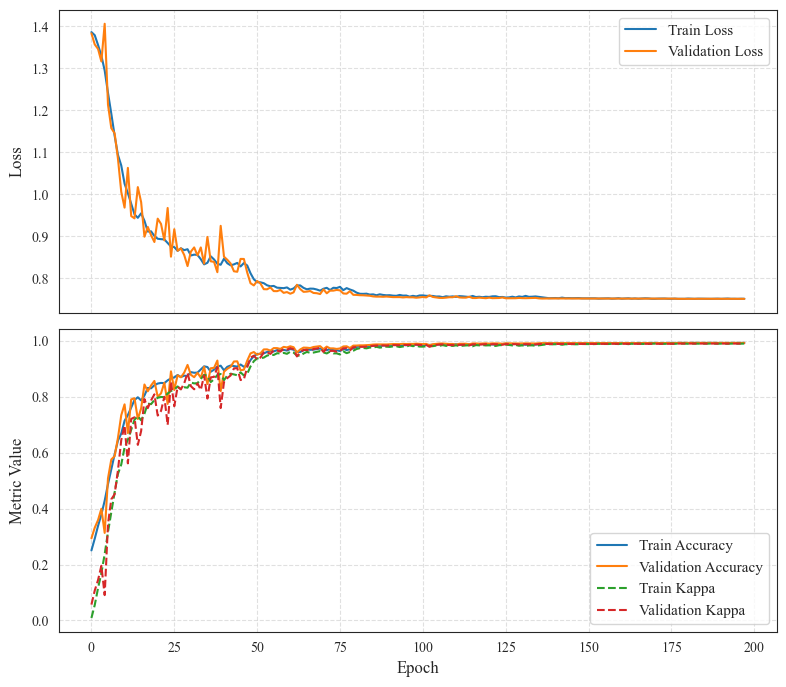

In [23]:
log_subject_invariant.rename(columns={'val__kappa': 'val_kappa'}, inplace=True)

# Set Times New Roman globally
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "legend.fontsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 14
})

# Create subplots
fig, axs = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

# --- Plot 1: Loss ---
axs[0].plot(log_subject_invariant['train_loss'], label='Train Loss', color='#1f77b4', linewidth=1.5)
axs[0].plot(log_subject_invariant['val_loss'], label='Validation Loss', color='#ff7f0e', linewidth=1.5)
axs[0].set_ylabel('Loss')
axs[0].grid(True, linestyle='--', alpha=0.6)
axs[0].legend()

# --- Plot 2: Accuracy and Kappa ---
axs[1].plot(log_subject_invariant['train_acc'], label='Train Accuracy', color='#1f77b4', linewidth=1.5)
axs[1].plot(log_subject_invariant['val_acc'], label='Validation Accuracy', color='#ff7f0e', linewidth=1.5)
axs[1].plot(log_subject_invariant['train_kappa'], label='Train Kappa', color='#2ca02c', linestyle='--', linewidth=1.5)
axs[1].plot(log_subject_invariant['val_kappa'], label='Validation Kappa', color='#d62728', linestyle='--', linewidth=1.5)
axs[1].set_xlabel('Epoch')
axs[1].set_ylabel('Metric Value')
axs[1].grid(True, linestyle='--', alpha=0.6)
axs[1].legend()

# Optional: Add overall title
# fig.suptitle('Training Dynamics', fontsize=14, fontweight='bold')

plt.tight_layout()
# plt.savefig('training_curves.pdf', dpi=300, bbox_inches='tight')  # Uncomment to save
plt.show()

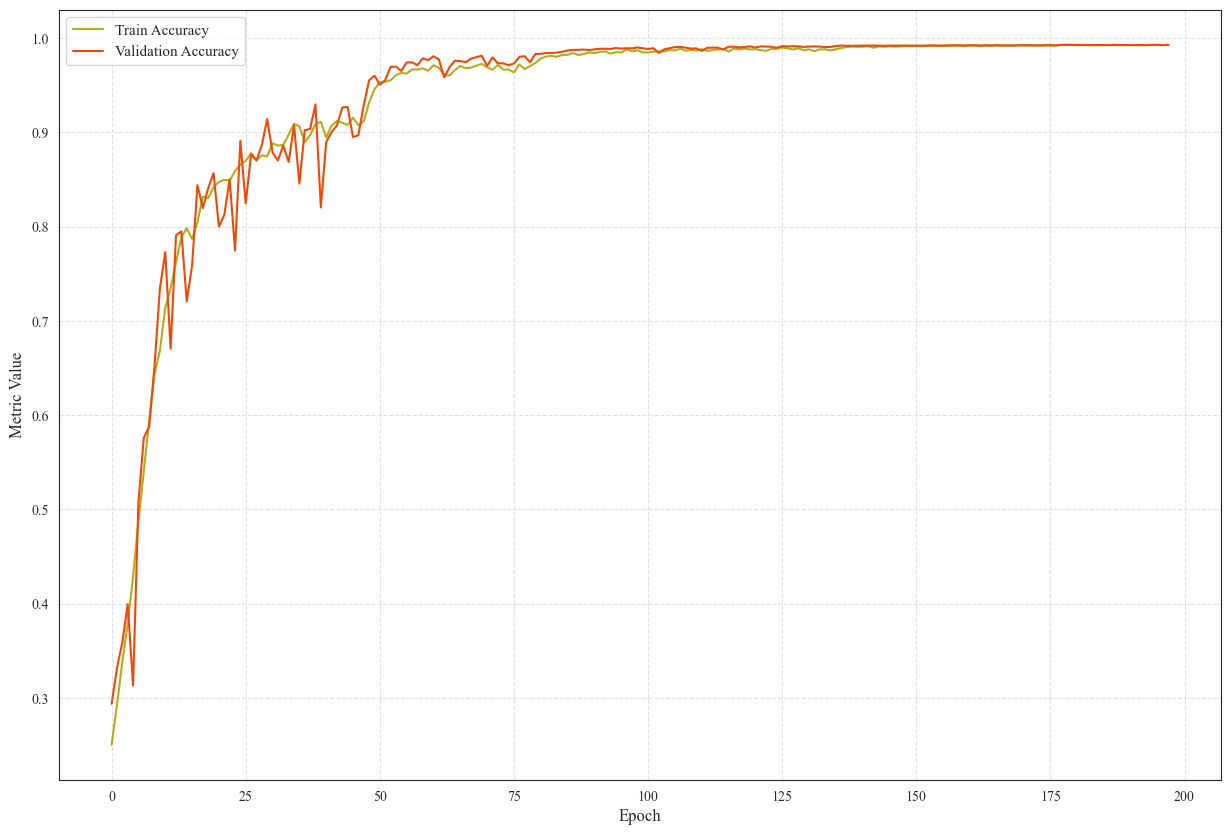

In [24]:
# Set Times New Roman globally
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "legend.fontsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 14
})

# Create subplots
plt.figure(figsize=(15,10))
# --- Plot 2: Accuracy and Kappa ---
plt.plot(log_subject_invariant['train_acc'], label='Train Accuracy', color="#B6AB19", linewidth=1.5)
plt.plot(log_subject_invariant['val_acc'], label='Validation Accuracy', color="#F04907", linewidth=1.5)
plt.xlabel('Epoch')
plt.ylabel('Metric Value')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()


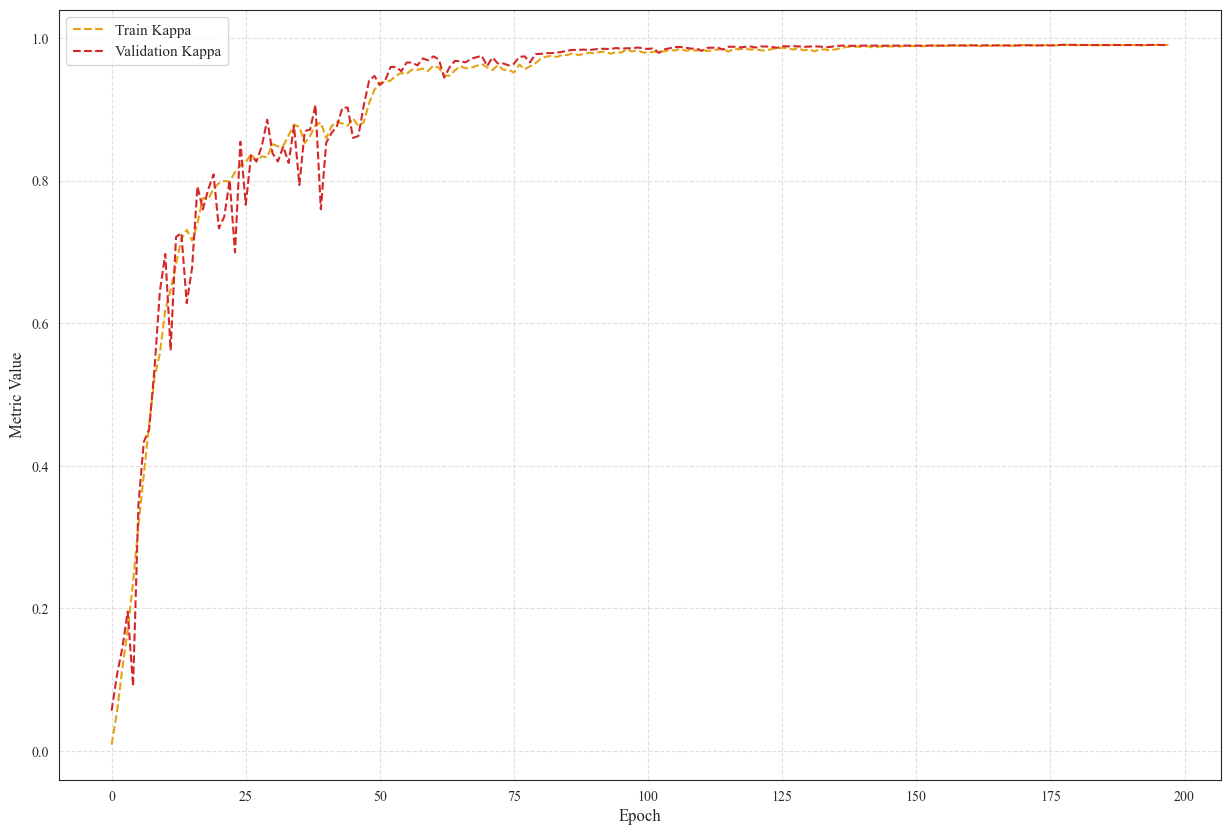

In [25]:
# Set Times New Roman globally
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "legend.fontsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 14
})

# Create subplots
plt.figure(figsize=(15,10))

plt.plot(log_subject_invariant['train_kappa'], label='Train Kappa', color="#E6A212", linestyle='--', linewidth=1.5)
plt.plot(log_subject_invariant['val_kappa'], label='Validation Kappa', color='#d62728', linestyle='--', linewidth=1.5)
plt.xlabel('Epoch')
plt.ylabel('Metric Value')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()


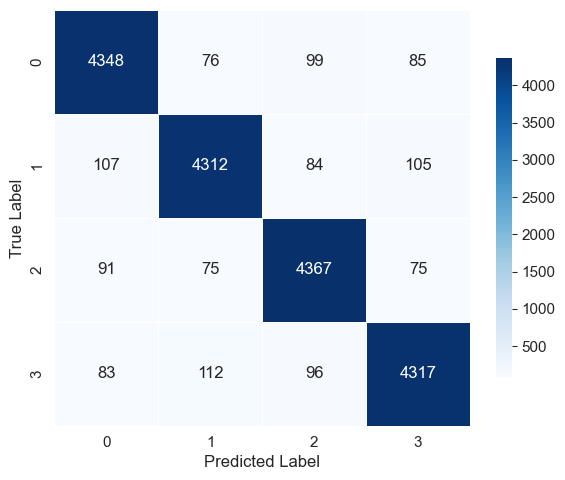

0.9410
0.9213


In [32]:
# --- Set Times New Roman globally ---
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11
})

y_true = test_results_subjectwise['y_true']
y_pred = test_results_subjectwise['y_pred']

# --- Compute confusion matrix ---
cm = confusion_matrix(y_true, y_pred)
num_classes = cm.shape[0]

# --- Labels (assuming classes are 0, 1, 2, 3) ---
labels = sorted(np.unique(np.concatenate([y_true, y_pred])))

# --- Plot ---
plt.figure(figsize=(6, 5))
sns.set_style("white")

ax = sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels,
    cbar_kws={'shrink': 0.75},
    linewidths=0.5,
    linecolor='white'
)

# Labels and title
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

# Ensure square cells
ax.set_aspect('equal')

# Optional: Save high-resolution figure
# plt.savefig('confusion_matrix.pdf', dpi=300, bbox_inches='tight')
test_accuracy = accuracy_score(y_pred=y_pred, y_true=y_true)
kappa_score = cohen_kappa_score(y1=y_pred, y2=y_true)
plt.tight_layout()
plt.show()
print(f"{test_accuracy:.4f}")
print(f"{kappa_score:.4f}")

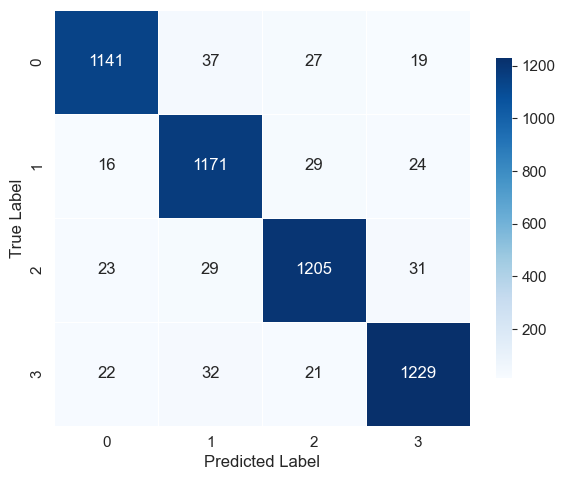

0.9387
0.9182


In [ ]:
# --- Set Times New Roman globally ---
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11
})

y_true = test_results_subjectinvariant['y_true']
y_pred = test_results_subjectinvariant['y_pred']

# --- Compute confusion matrix ---
cm = confusion_matrix(y_true, y_pred)
num_classes = cm.shape[0]

# --- Labels (assuming classes are 0, 1, 2, 3) ---
labels = sorted(np.unique(np.concatenate([y_true, y_pred])))

# --- Plot ---
plt.figure(figsize=(6, 5))
sns.set_style("white")

ax = sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels,
    cbar_kws={'shrink': 0.75},
    linewidths=0.5,
    linecolor='white'
)

# Labels and title
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

# Ensure square cells
ax.set_aspect('equal')

# Optional: Save high-resolution figure
# plt.savefig('confusion_matrix.pdf', dpi=300, bbox_inches='tight')

test_accuracy = accuracy_score(y_pred=y_pred, y_true=y_true)
kappa_score = cohen_kappa_score(y1=y_pred, y2=y_true)
plt.tight_layout()
plt.show()
print(f"{test_accuracy:.4f}")
print(f"{kappa_score:.4f}")

# **Albumentations Study**

EEGNet Block